In [32]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.pipeline import make_pipeline
from scipy.stats import f_oneway
from scipy.stats import chi2_contingency
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import ParameterSampler
from sklearn.mixture import GaussianMixture
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import SGDOneClassSVM
from sklearn.ensemble import IsolationForest
from sklearn.metrics import f1_score,accuracy_score,classification_report

## About Dataset
The UNSW-NB15 dataset was generated in the Cyber Range Lab at UNSW Canberra with the IXIA PerfectStorm tool. It captures a hybrid of realistic benign traffic and nine modern attack families—Fuzzers, Analysis, Backdoors, DoS, Exploits, Generic, Reconnaissance, Shellcode, Worms—all recorded as raw pcap files and distilled into flow-level CSVs. In our project we will try to predict intrusion-detection

## About Attributes:
- srcip,nominal,Source IP address
- sport,integer,Source port number
- dstip,nominal,Destination IP address
- dsport,integer,Destination port number
- proto,nominal,Transaction protocol
- state,nominal,"Indicates to the state and its dependent protocol, e.g. ACC, CLO, CON, ECO, ECR, FIN, INT, MAS, PAR, REQ, RST, TST, TXD, URH, URN, and (-) (if not used state)"
- dur,Float,Record total duration
- sbytes,Integer,Source to destination transaction bytes 
- dbytes,Integer,Destination to source transaction bytes
- sttl,Integer,Source to destination time to live value 
- dttl,Integer,Destination to source time to live value
- sloss,Integer,Source packets retransmitted or dropped 
- dloss,Integer,Destination packets retransmitted or dropped
- service,nominal,"http, ftp, smtp, ssh, dns, ftp-data ,irc  and (-) if not much used service"
- Sload,Float,Source bits per second
- Dload,Float,Destination bits per second
- Spkts,integer,Source to destination packet count 
- Dpkts,integer,Destination to source packet count
- swin,integer,Source TCP window advertisement value
- dwin,integer,Destination TCP window advertisement value
- stcpb,integer,Source TCP base sequence number
- dtcpb,integer,Destination TCP base sequence number
- smeansz,integer,Mean of the ?ow packet size transmitted by the src 
- dmeansz,integer,Mean of the ?ow packet size transmitted by the dst 
- trans_depth,integer,Represents the pipelined depth into the connection of http request/response transaction
- res_bdy_len,integer,Actual uncompressed content size of the data transferred from the server s http service.
- Sjit,Float,Source jitter (mSec)
- Djit,Float,Destination jitter (mSec)
- Stime,Timestamp,record start time
- Ltime,Timestamp,record last time
- Sintpkt,Float,Source interpacket arrival time (mSec)
- Dintpkt,Float,Destination interpacket arrival time (mSec)
- tcprtt,Float,"TCP connection setup round-trip time, the sum of  synack  and  ackdat ."
- synack,Float,"TCP connection setup time, the time between the SYN and the SYN_ACK packets."
- ackdat,Float,"TCP connection setup time, the time between the SYN_ACK and the ACK packets."
- is_sm_ips_ports,Binary,"If source (1) and destination (3)IP addresses equal and port numbers (2)(4)  equal then, this variable takes value 1 else 0"
- ct_state_ttl,Integer,No. for each state (6) according to specific range of values for source/destination time to live (10) (11).
- ct_flw_http_mthd,Integer,No. of flows that has methods such as Get and Post in http service.
- is_ftp_login,Binary,If the ftp session is accessed by user and password then 1 else 0. 
- ct_ftp_cmd,integer,No of flows that has a command in ftp session.
- ct_srv_src,integer,No. of connections that contain the same service (14) and source address (1) in 100 connections according to the last time (26).
- ct_srv_dst,integer,No. of connections that contain the same service (14) and destination address (3) in 100 connections according to the last time (26).
- ct_dst_ltm,integer,No. of connections of the same destination address (3) in 100 connections according to the last time (26).
- ct_src_ ltm,integer,No. of connections of the same source address (1) in 100 connections according to the last time (26).
- ct_src_dport_ltm,integer,No of connections of the same source address (1) and the destination port (4) in 100 connections according to the last time (26).
- ct_dst_sport_ltm,integer,No of connections of the same destination address (3) and the source port (2) in 100 connections according to the last time (26).
- ct_dst_src_ltm,integer,No of connections of the same source (1) and the destination (3) address in in 100 connections according to the last time (26).
- attack_cat,nominal,"The name of each attack category. In this data set , nine categories e.g. Fuzzers, Analysis, Backdoors, DoS Exploits, Generic, Reconnaissance, Shellcode and Worms"
- Label,binary,0 for normal and 1 for attack records

In [17]:
# Load data

files = [
    "UNSW-NB15_1.csv",
    "UNSW-NB15_2.csv",
    "UNSW-NB15_3.csv",
    "UNSW-NB15_4.csv"
]

df = pd.concat(
    [pd.read_csv(file, header=None,low_memory=False) for file in files],
    ignore_index=True
)
df.columns=['srcip','sport','dstip','dsport','proto','state','dur','sbytes','dbytes','sttl','dttl','sloss','dloss','service','Sload','Dload','Spkts','Dpkts','swin',
 'dwin','stcpb','dtcpb','smeansz','dmeansz','trans_depth','res_bdy_len','Sjit','Djit','Stime','Ltime','Sintpkt','Dintpkt','tcprtt','synack','ackdat',
 'is_sm_ips_ports','ct_state_ttl','ct_flw_http_mthd','is_ftp_login','ct_ftp_cmd','ct_srv_src','ct_srv_dst','ct_dst_ltm','ct_src_ ltm','ct_src_dport_ltm',
 'ct_dst_sport_ltm','ct_dst_src_ltm','attack_cat','Label']

df.head()

,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,attack_cat,Label
0,59.166.0.0,1390,149.171.126.6,53,udp,CON,0.001055,132,164,31,...,0,3,7,1,3,1,1,1,NaN,0
1,59.166.0.0,33661,149.171.126.9,1024,udp,CON,0.036133,528,304,31,...,0,2,4,2,3,1,1,2,NaN,0
2,59.166.0.6,1464,149.171.126.7,53,udp,CON,0.001119,146,178,31,...,0,12,8,1,2,2,1,1,NaN,0
3,59.166.0.5,3593,149.171.126.5,53,udp,CON,0.001209,132,164,31,...,0,6,9,1,1,1,1,1,NaN,0
4,59.166.0.3,49664,149.171.126.0,53,udp,CON,0.001169,146,178,31,...,0,7,9,1,1,1,1,1,NaN,0


## Data Preprocessing

In [18]:
# Data Summary
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2540047 entries, 0 to 2540046
Data columns (total 49 columns):
 #   Column            Dtype  
---  ------            -----  
 0   srcip             object 
 1   sport             object 
 2   dstip             object 
 3   dsport            object 
 4   proto             object 
 5   state             object 
 6   dur               float64
 7   sbytes            int64  
 8   dbytes            int64  
 9   sttl              int64  
 10  dttl              int64  
 11  sloss             int64  
 12  dloss             int64  
 13  service           object 
 14  Sload             float64
 15  Dload             float64
 16  Spkts             int64  
 17  Dpkts             int64  
 18  swin              int64  
 19  dwin              int64  
 20  stcpb             int64  
 21  dtcpb             int64  
 22  smeansz           int64  
 23  dmeansz           int64  
 24  trans_depth       int64  
 25  res_bdy_len       int64  
 26  Sjit          

In [19]:
# Drop useless columns 
drop_cols = df.drop(columns=["srcip","dstip","attack_cat"],inplace=True)

In [20]:
# Adjust dtypes
df["sport"] = pd.to_numeric(df["sport"], errors="coerce")
df["dsport"] = pd.to_numeric(df["dsport"], errors="coerce")
df["ct_ftp_cmd"] = pd.to_numeric(df["ct_ftp_cmd"], errors="coerce")

In [21]:
# Replace missing data with np.nan
df.replace({'-':np.nan,'':np.nan}, inplace=True)

In [22]:
# Missing Data Info ; numbers show number of missing data
print('**Missing Data**')
df.isnull().sum()

**Missing Data**


sport                     8
dsport                  304
proto                     0
state                     0
dur                       0
sbytes                    0
dbytes                    0
sttl                      0
dttl                      0
sloss                     0
dloss                     0
service             1246397
Sload                     0
Dload                     0
Spkts                     0
Dpkts                     0
swin                      0
dwin                      0
stcpb                     0
dtcpb                     0
smeansz                   0
dmeansz                   0
trans_depth               0
res_bdy_len               0
Sjit                      0
Djit                      0
Stime                     0
Ltime                     0
Sintpkt                   0
Dintpkt                   0
tcprtt                    0
synack                    0
ackdat                    0
is_sm_ips_ports           0
ct_state_ttl              0
ct_flw_http_mthd    

In [23]:
# Print out feature names with  missing data
missing_columns=df.columns[df.isnull().any()].tolist()
missing_columns

['sport',
 'dsport',
 'service',
 'ct_flw_http_mthd',
 'is_ftp_login',
 'ct_ftp_cmd']

In [24]:
# Select predictors and target
X = df.drop('Label',axis=1)
y = df["Label"]

In [25]:
# Select data into X_train,X_val,X_test

X_normal=X.loc[y==0]
X_anomaly=X.loc[y==1]


X_train, X_temp_normal = train_test_split(
    X_normal,
    test_size=0.30,
    random_state=42)

X_val_normal, X_test_normal = train_test_split(
    X_temp_normal,
    test_size=0.50,
    random_state=42)


normal_count = len(X_normal)
anomaly_count = len(X_anomaly)

anomaly_rate = anomaly_count / (normal_count + anomaly_count)


n_val_anomaly = int(
    len(X_val_normal) *
    anomaly_rate /
    (1 - anomaly_rate))

n_test_anomaly = int(
    len(X_test_normal) *
    anomaly_rate /
    (1 - anomaly_rate))


X_val_anomaly = X_anomaly.sample(
    n=n_val_anomaly,
    random_state=42
)

remaining_anomaly = X_anomaly.drop(
    X_val_anomaly.index
)

X_test_anomaly = remaining_anomaly.sample(
    n=n_test_anomaly,
    random_state=42
)


X_val = pd.concat(
    [X_val_normal, X_val_anomaly],axis=0)

y_val = np.concatenate([
    np.zeros(len(X_val_normal)),   # normal = 0
    np.ones(len(X_val_anomaly))    # anomaly = 1
])

# Create final unseen test set

X_test = pd.concat(
    [X_test_normal, X_test_anomaly],axis=0)

y_test = np.concatenate([
    np.zeros(len(X_test_normal)),
    np.ones(len(X_test_anomaly))
])
print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(1553134, 45)
(381007, 45)
(381007, 45)


In [27]:
# Encode your categoric data and apply standard scaling to numeric ones &  Remove data with zero variance.
nominal_cols=['proto',
              'state',
              'service']
num_cols=X_train.select_dtypes(include=['int64','float64']).columns.tolist()


# 1. Numeric preprocessing
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler', StandardScaler()),
])



# 2. Categorical preprocessing for nominal features
nominal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='first',
        handle_unknown='ignore',
        sparse_output=False
    ))
])

# 3. Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ('numeric', numeric_pipeline, num_cols),
        ('nominal', nominal_pipeline, nominal_cols)
    ],remainder='passthrough',
      verbose_feature_names_out=False  # Remove transformer prefixes
)


# 4. Complete preprocessing pipeline
full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('variance_selector', VarianceThreshold(threshold=0.1)),
    ('pca',PCA(n_components=0.95))
     ])

# 5. Fit ONLY on training data
full_pipeline.set_output(transform='pandas')

X_train = full_pipeline.fit_transform(X_train)

# 6. Transform test data without refitting
X_test = full_pipeline.transform(X_test)
X_val = full_pipeline.transform(X_val)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test.shape)

C:\Users\goher\anaconda3\envs\ds_env\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
C:\Users\goher\anaconda3\envs\ds_env\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0, 2] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Training shape: (1553134, 23)
Validation shape: (381007, 23)
Testing shape: (381007, 23)


## Exploratory Analysis

In [28]:
# Chi_2 test  for categoric predictors and categoric target
target = y
predictors = df.select_dtypes(include=["object", "string"]).columns.tolist()

# 2. Compute Chi-Square test for each predictor
results = []
for col in predictors:
        # Combine feature and target, then remove missing values
    temp = pd.DataFrame({
        "feature": df[col],
        "target": target
    }).dropna()

    # Build contingency table
    contingency_table = pd.crosstab(
        temp["feature"],
        temp["target"]
    )
    
    # Calculate Chi-Square statistics
    chi2, p_value, dof, expected = chi2_contingency(contingency_table)
    
    results.append({
        'Feature': col,
        'Chi2 Statistic': chi2,
        'p-value': p_value,
        'Significant (α=0.05)': 'Yes' if p_value < 0.05 else 'No'
    })

# Convert to DataFrame to view results cleanly
results_df = pd.DataFrame(results)
print("--- Chi-Square Test Results ---")
print(results_df)

--- Chi-Square Test Results ---
   Feature  Chi2 Statistic  p-value Significant (α=0.05)
0    proto   449122.969709      0.0                  Yes
1    state   907673.334961      0.0                  Yes
2  service   105088.922168      0.0                  Yes


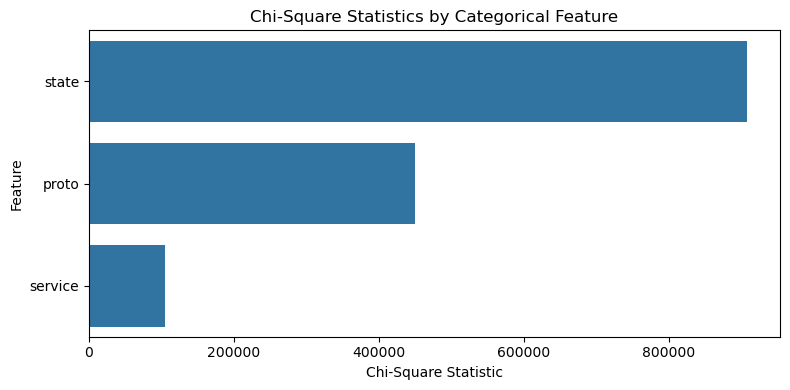

In [33]:
# Sort features by Chi-square statistic
plot_df = results_df.sort_values(
    "Chi2 Statistic", ascending=False
)

plt.figure(figsize=(8, 4))

sns.barplot(
    data=plot_df,
    x="Chi2 Statistic",
    y="Feature"
)

plt.title("Chi-Square Statistics by Categorical Feature")
plt.xlabel("Chi-Square Statistic")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [34]:
# Skewness of data
df.select_dtypes("number").agg(["skew","kurtosis"]).T

,skew,kurtosis
sport,-0.047602,-1.328977
dsport,1.576200,1.112121
dur,590.036391,371440.470936
sbytes,142.981858,24006.582106
dbytes,9.089084,261.867215
sttl,2.132909,2.654117
dttl,4.548566,20.915378
sloss,118.739427,18653.410296
dloss,9.428584,321.645363
Sload,7.525025,118.998906


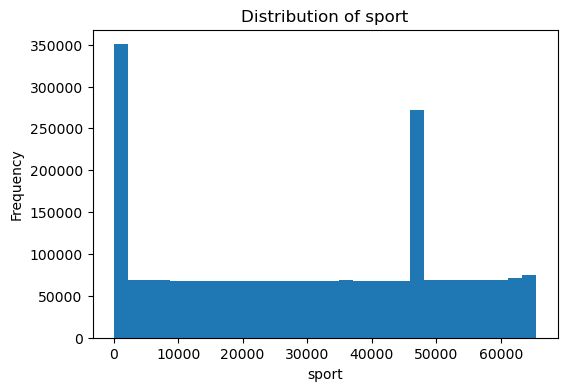

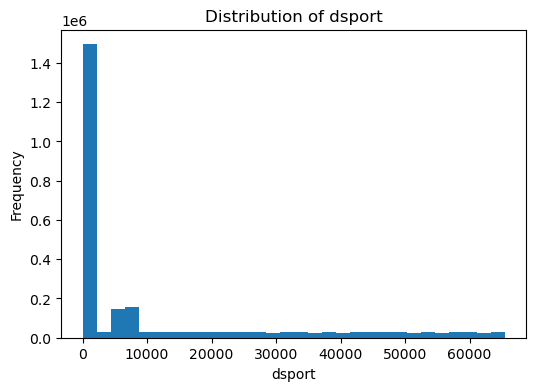

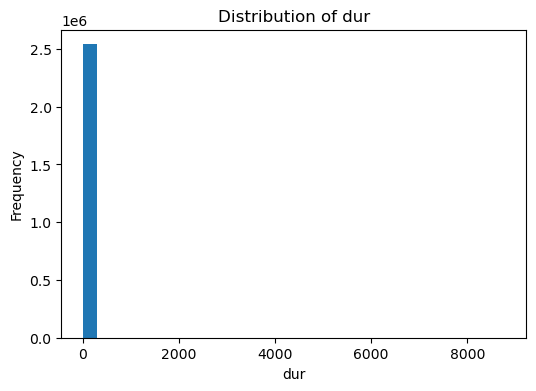

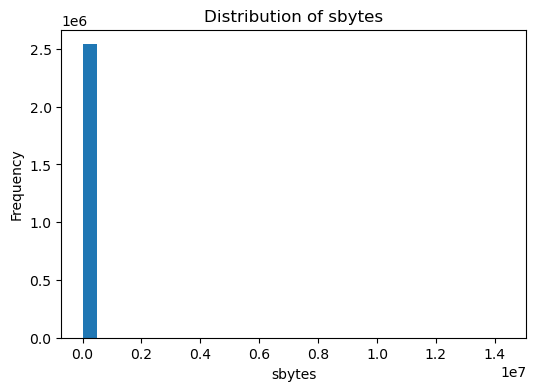

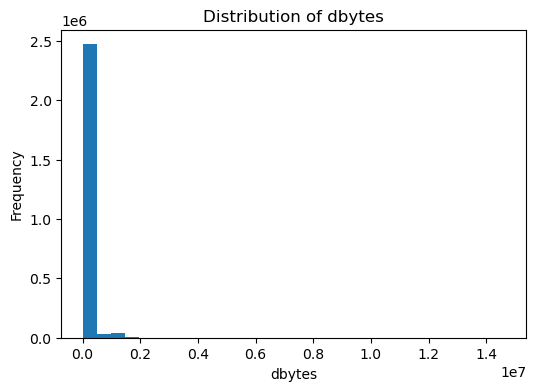

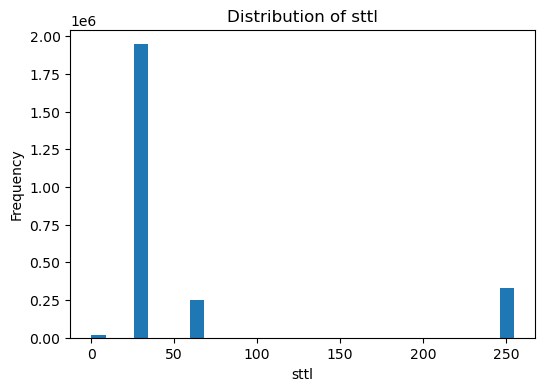

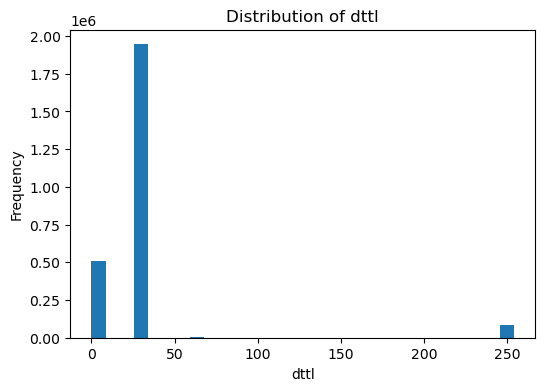

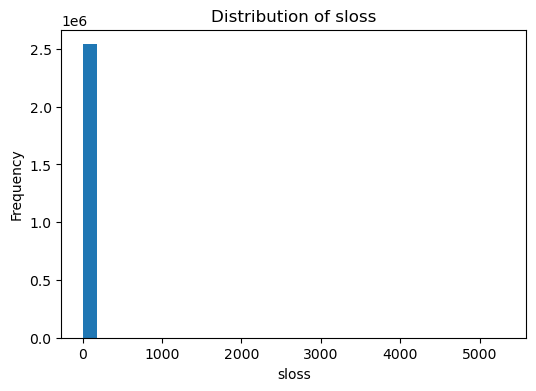

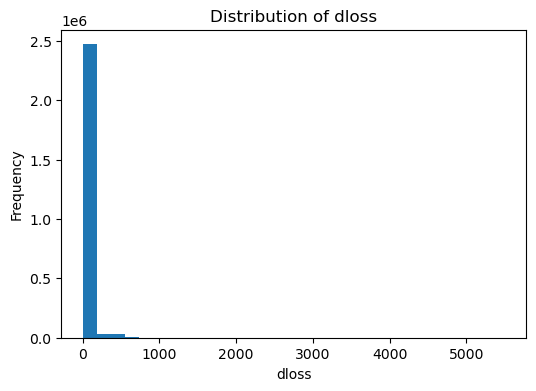

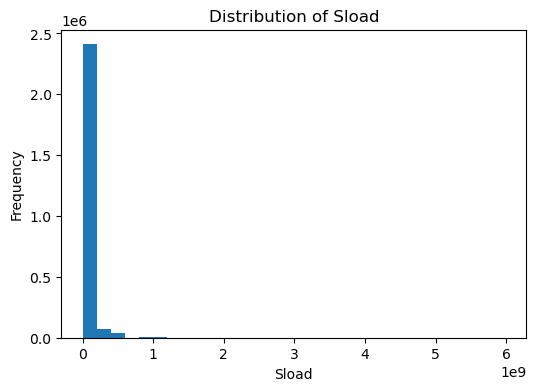

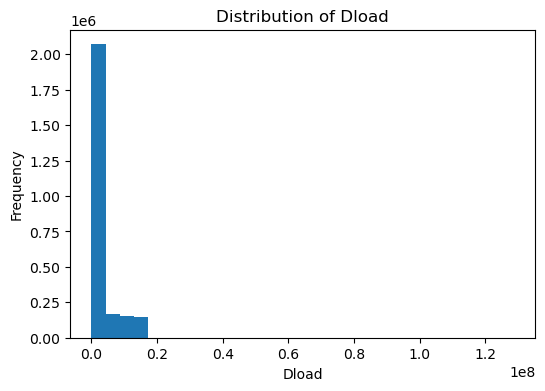

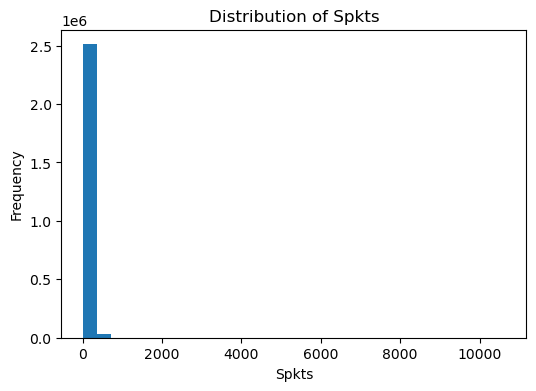

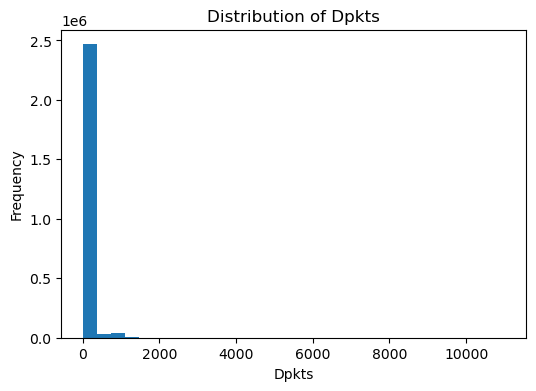

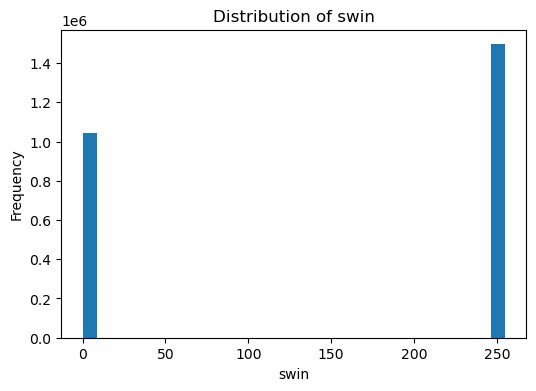

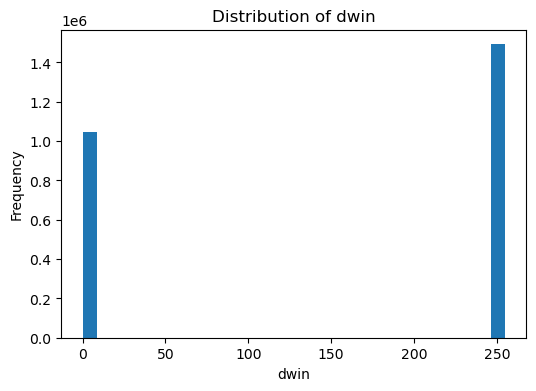

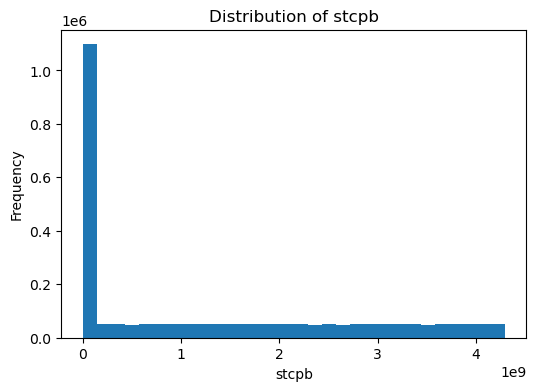

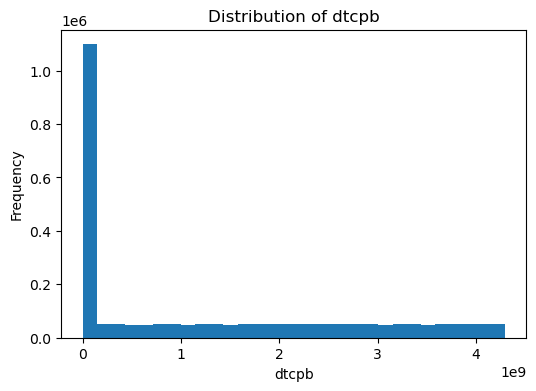

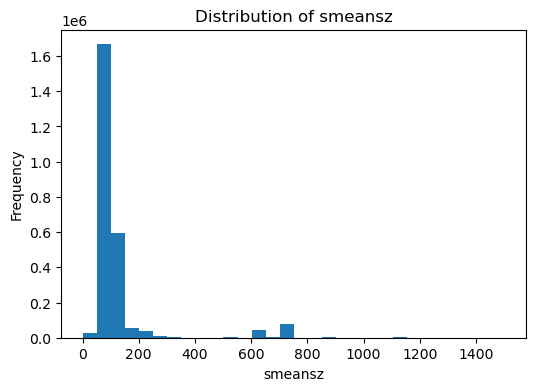

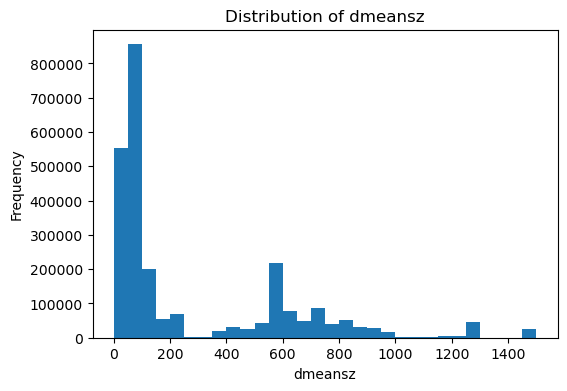

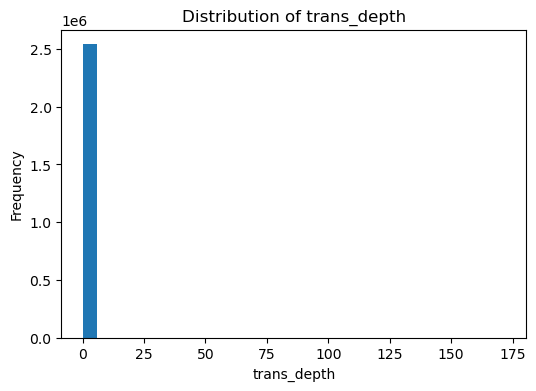

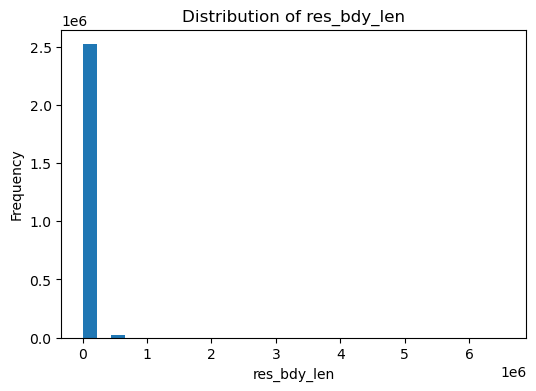

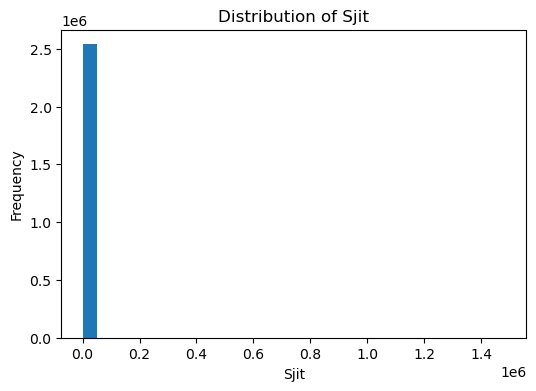

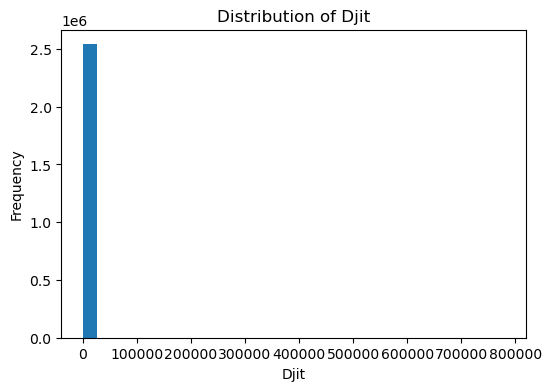

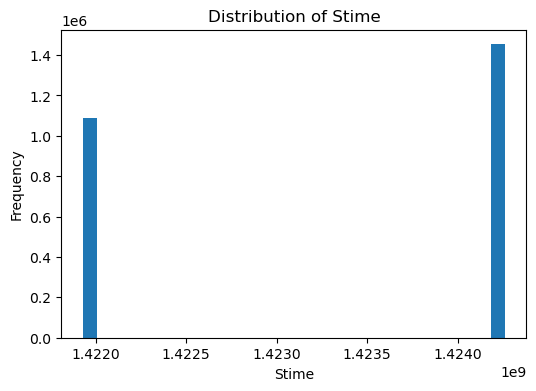

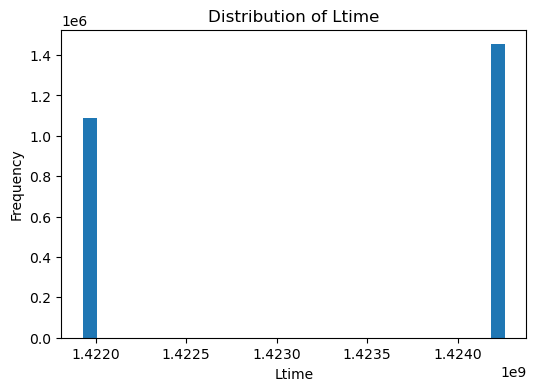

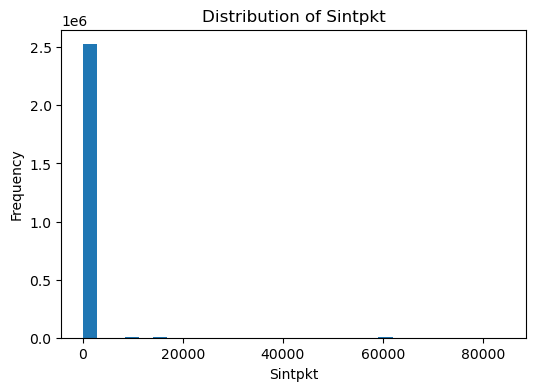

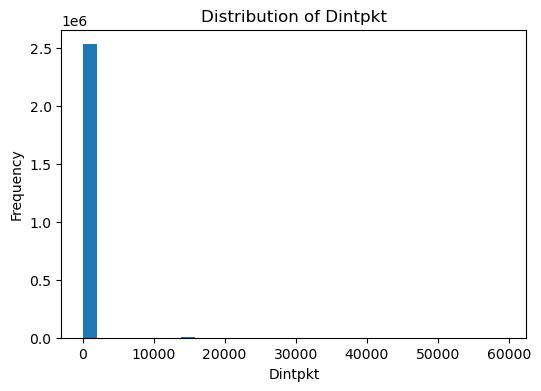

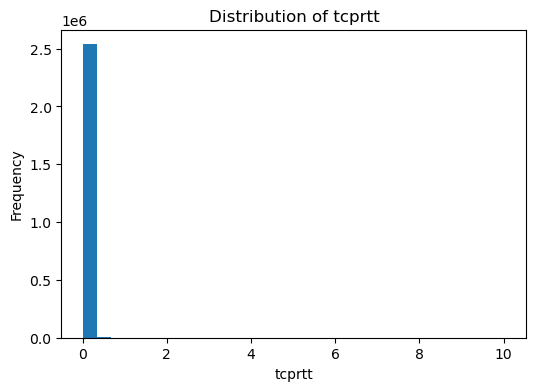

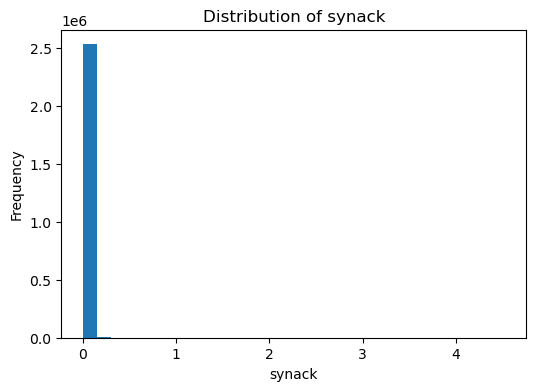

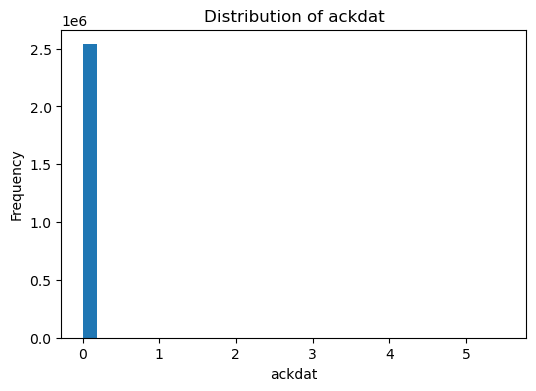

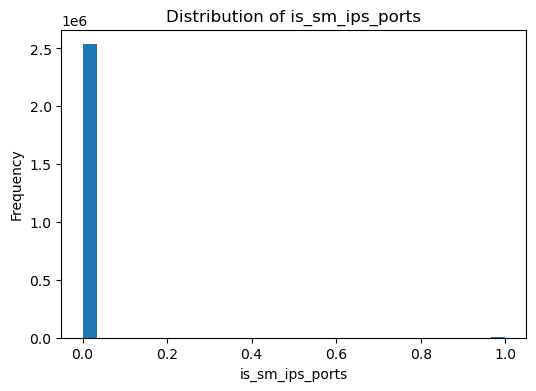

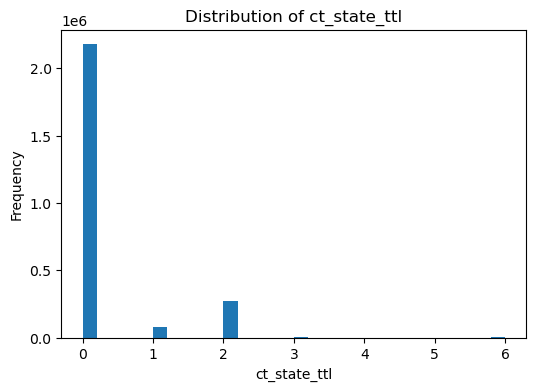

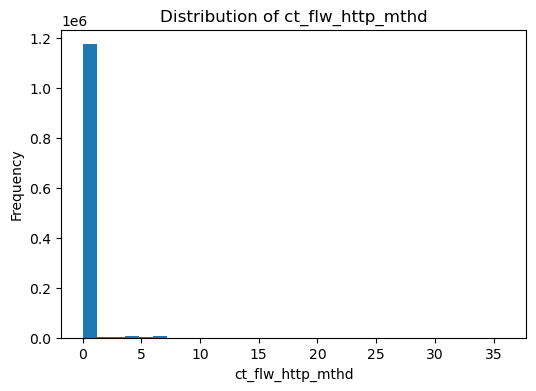

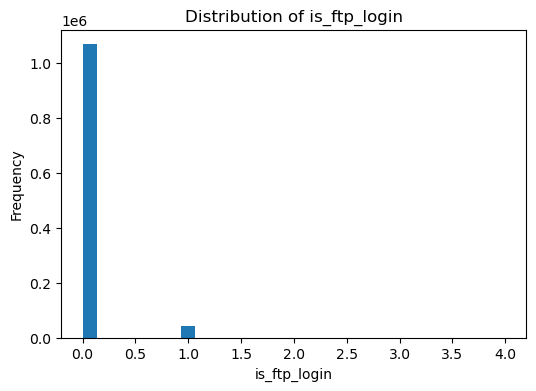

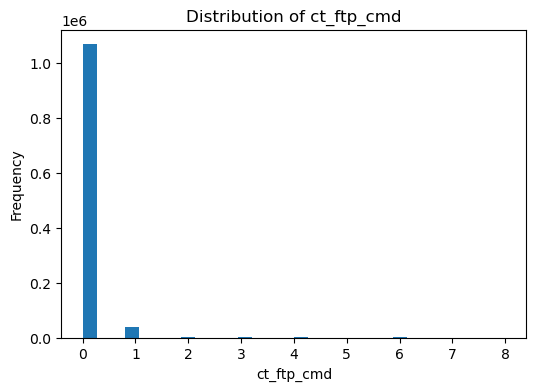

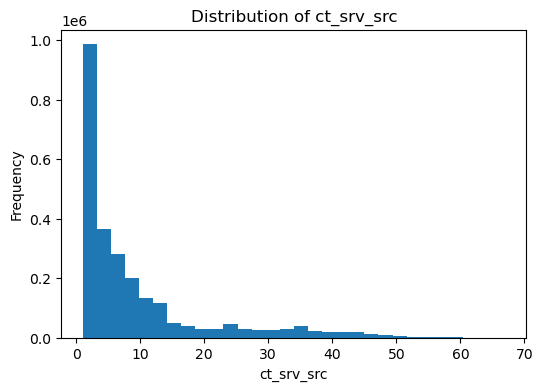

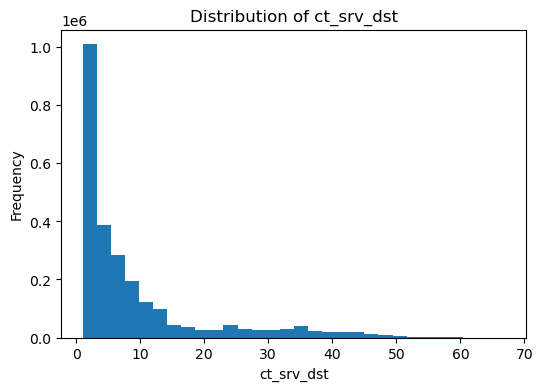

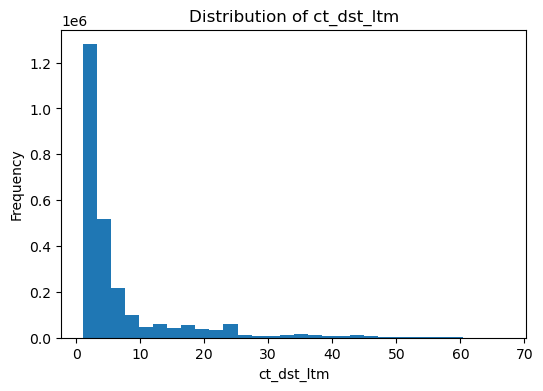

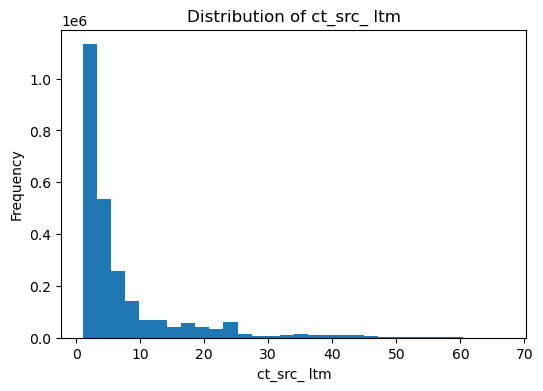

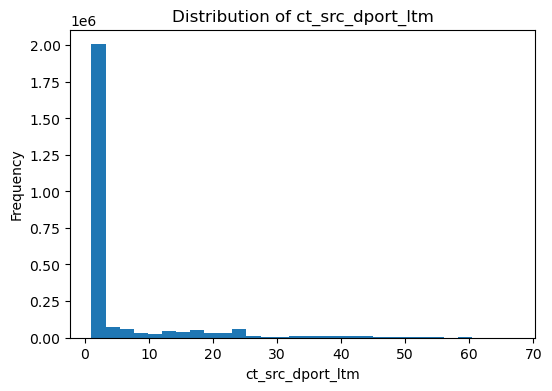

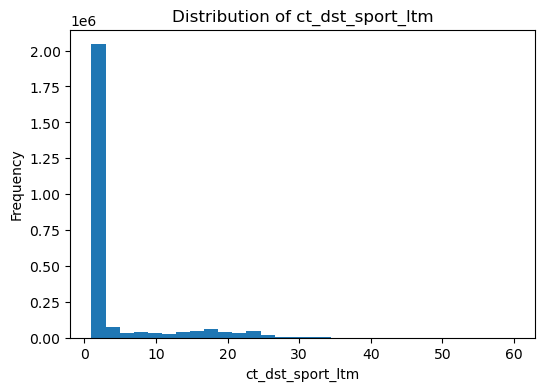

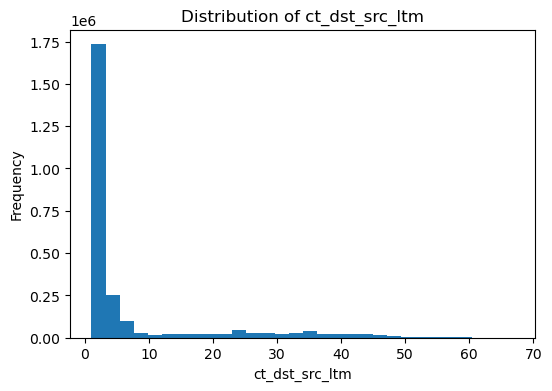

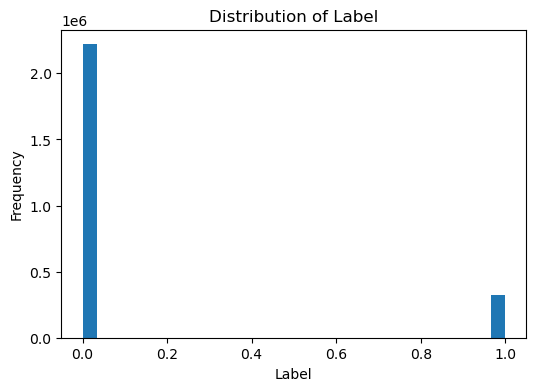

In [35]:
# Data skewness visualization
import matplotlib.pyplot as plt

numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    plt.figure(figsize=(6, 4))
    plt.hist(df[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

## Models

In [19]:
# Reproducible sampling

# --------------------------------------------------
# 1. Random sampling of normal training data
# --------------------------------------------------
rng = np.random.default_rng(42)

train_idx = rng.choice(
    len(X_train),
    size=min(20_000, len(X_train)),
    replace=False
)

X_train_sample = (
    X_train.iloc[train_idx]
    if hasattr(X_train, "iloc")
    else X_train[train_idx]
)

# --------------------------------------------------
# 2. Stratified sampling of validation data
# --------------------------------------------------
val_idx, _ = train_test_split(
    np.arange(len(X_val)),
    train_size=min(10_000, len(X_val)),
    stratify=np.asarray(y_val),
    random_state=42
)

X_val_sample = (
    X_val.iloc[val_idx]
    if hasattr(X_val, "iloc")
    else X_val[val_idx]
)

y_val_sample = (
    y_val.iloc[val_idx]
    if hasattr(y_val, "iloc")
    else np.asarray(y_val)[val_idx]
)

# --------------------------------------------------
# 3. Check anomaly distribution
# --------------------------------------------------
print("Training sample shape:", X_train_sample.shape)
print("Validation sample shape:", X_val_sample.shape)

print("\nOriginal validation anomaly ratio:")
print(np.mean(np.asarray(y_val) == 1))

print("\nSample validation anomaly ratio:")
print(np.mean(np.asarray(y_val_sample) == 1))

print("\nSample class counts:")
print(np.unique(y_val_sample, return_counts=True))

Training sample shape: (20000, 23)
Validation sample shape: (10000, 23)

Original validation anomaly ratio:
0.12648586508909285

Sample validation anomaly ratio:
0.1265

Sample class counts:
(array([0., 1.]), array([8735, 1265]))


In [19]:
# Select Best Number of Components for GMM

bic_scores = []

for k in range(1, 11):

    gmm = GaussianMixture(
        n_components=k,
        covariance_type="full",
        n_init=1,
        reg_covar=1e-6,
        max_iter=50,
        random_state=42,
        tol=1e-3
    )

    gmm.fit(X_train_sample)

    bic_scores.append(gmm.bic(X_train_sample))

best_k = np.argmin(bic_scores) + 1                 

print("Best Components:", best_k)
print("BIC_score",np.min(bic_scores))   # Lower BIC = better model

Best Components: 10
BIC_score -1454867.0071279795


In [20]:
# ============================================================
# GMM hyperparameter combinations
# ============================================================
                                                          
parameters = {
    "n_components": [best_k],
    "covariance_type": [ "full", "diag", "tied",  "spherical"],  
    "reg_covar": [ 1e-5, 1e-4]
}


# ============================================================
# Manual hyperparameter search
# ============================================================

best_score = -np.inf
best_params = None
best_threshold = None

for params in ParameterSampler(
    parameters,
    n_iter=4,
    random_state=42
):

    # --------------------------------------------------------
    # Create GMM
    # --------------------------------------------------------

    model = GaussianMixture(
        **params,
        random_state=42
    )

    # --------------------------------------------------------
    # Train ONLY on normal data
    # --------------------------------------------------------

    model.fit(X_train_sample)

    # --------------------------------------------------------
    # Calculate log-likelihood scores
    # Higher = more normal
    # Lower = more anomalous
    # --------------------------------------------------------

    val_scores = model.score_samples(X_val_sample)


    # --------------------------------------------------------
    # Find threshold using validation data
    #
    # Samples with score < threshold = anomaly
    # Samples with score >= threshold = normal
    # --------------------------------------------------------

    thresholds = np.percentile(val_scores,np.arange(1, 100))
    
    for threshold in thresholds:

        predictions = np.where(
            val_scores < threshold,
            1,      # anomaly
            0       # normal
        )

        score = f1_score(
            y_val_sample,
            predictions,
            zero_division=0
        )

        print(params, "F1:", score)

        if score > best_score:

            best_score = score
            best_params = params
            best_threshold = threshold


print("\nBest hyperparameters:")
print(best_params)

print("\nBest threshold:")
print(best_threshold)

print("\nBest validation F1:")
print(best_score)

{'reg_covar': 0.0001, 'n_components': np.int64(10), 'covariance_type': 'full'} F1: 0.10989010989010989
{'reg_covar': 0.0001, 'n_components': np.int64(10), 'covariance_type': 'full'} F1: 0.23071672354948805
{'reg_covar': 0.0001, 'n_components': np.int64(10), 'covariance_type': 'full'} F1: 0.32971246006389776
{'reg_covar': 0.0001, 'n_components': np.int64(10), 'covariance_type': 'full'} F1: 0.42162162162162165
{'reg_covar': 0.0001, 'n_components': np.int64(10), 'covariance_type': 'full'} F1: 0.49971671388101985
{'reg_covar': 0.0001, 'n_components': np.int64(10), 'covariance_type': 'full'} F1: 0.5737265415549598
{'reg_covar': 0.0001, 'n_components': np.int64(10), 'covariance_type': 'full'} F1: 0.6371501272264631
{'reg_covar': 0.0001, 'n_components': np.int64(10), 'covariance_type': 'full'} F1: 0.6808716707021791
{'reg_covar': 0.0001, 'n_components': np.int64(10), 'covariance_type': 'full'} F1: 0.7279445727482678
{'reg_covar': 0.0001, 'n_components': np.int64(10), 'covariance_type': 'full'

In [21]:
# Final  GMM model

best_model = GaussianMixture(
    **best_params,
    random_state=42
)

best_model.fit(X_train)


# Evaluate on completely unseen test data

test_scores = best_model.score_samples(X_test)


# Lower log-likelihood = anomaly
predictions = np.where(
    test_scores < best_threshold,
    1,      # anomaly
    0       # normal
)


print("F1:", f1_score(y_test, predictions))
print("Accuracy:", accuracy_score(y_test, predictions))
print("\nClassification Report:")
print(classification_report(y_test, predictions,target_names=["Normal", "Anomaly"],zero_division=0))

F1: 0.9056699864191942
Accuracy: 0.9737485138068329

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.97      0.98    332815
     Anomaly       0.83      1.00      0.91     48192

    accuracy                           0.97    381007
   macro avg       0.91      0.98      0.95    381007
weighted avg       0.98      0.97      0.97    381007



In [36]:
#Note: Use SGDOneClassSVM instead of OneClassSVM for large datasets

# ============================================================
#  Hyperparameter combinations SGDOneClassSVM with kernel='linear'
# ============================================================

parameters = {
    "nu": [0.01, 0.05],
    "max_iter": [500, 1000],
    "tol": [1e-3]
}

# ============================================================
#  Manual hyperparameter search
# ============================================================

best_score = -np.inf
best_params = None
best_model = None

for params in ParameterSampler(
    parameters,
    n_iter=4,
    random_state=42
):
    model = SGDOneClassSVM(
            **params,
            random_state=42,
            shuffle=True,
            learning_rate="optimal")


    # Train ONLY on normal training samples
    model.fit(X_train_sample)

    # Predict validation samples
    predictions = model.predict(X_val_sample)


    # Convert:
    # +1 normal  -> 0
    # -1 anomaly -> 1

    predictions = np.where(
        predictions == -1,
        1,
        0
    )

    score = f1_score(
        y_val_sample,
        predictions,
        zero_division=0
    )

    print(params, "F1:", score)

    if score > best_score:
        best_score = score
        best_params = params
        best_model = model

print("\nBest hyperparameters:", best_params)
print("Best validation F1:", best_score)


{'tol': 0.001, 'nu': 0.01, 'max_iter': 500} F1: 0.0
{'tol': 0.001, 'nu': 0.05, 'max_iter': 500} F1: 0.0
{'tol': 0.001, 'nu': 0.01, 'max_iter': 1000} F1: 0.0
{'tol': 0.001, 'nu': 0.05, 'max_iter': 1000} F1: 0.0

Best hyperparameters: {'tol': 0.001, 'nu': 0.01, 'max_iter': 500}
Best validation F1: 0.0


In [39]:
# ============================================================
#   Final  SGDOneClassSVM model 
# ============================================================

best_model = SGDOneClassSVM(
    **best_params,
    random_state=42,
    shuffle=True,
    learning_rate="optimal")


best_model.fit(X_train)

# ============================================================
#  Evaluate on test data
# ============================================================

predictions = best_model.predict(X_test)


    # Convert:
    # +1 normal  -> 0
    # -1 anomaly -> 1

predictions = np.where(
    predictions == -1,
    1,
    0
)

print("\nTest F1:", f1_score(
    y_test, predictions, zero_division=0
))

print("Test Accuracy:", accuracy_score(
    y_test, predictions
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))


Test F1: 0.0
Test Accuracy: 0.8735141349109071

Classification Report:
              precision    recall  f1-score   support

      Normal       0.87      1.00      0.93    332815
     Anomaly       0.00      0.00      0.00     48192

    accuracy                           0.87    381007
   macro avg       0.44      0.50      0.47    381007
weighted avg       0.76      0.87      0.81    381007



In [40]:


# ============================================================
#  Hyperparameter combinations for SGDOneClassSVM with kernel='rbf'
# ============================================================

parameters = {
    "nu": [0.01, 0.05],
    "gamma": [0.01,0.05],
    "n_components": [100, 200],
    "max_iter": [500, 1000]
}

# ============================================================
#  Manual hyperparameter search
# ============================================================

best_score = -np.inf
best_params = None

for params in ParameterSampler(
    parameters,
    n_iter=4,
    random_state=42
):

    print("Testing:", params)

    # Separate Nystroem parameters from SGD parameters
    model = make_pipeline(

        Nystroem(
            kernel="rbf",
            gamma=params["gamma"],
            n_components=params["n_components"],
            random_state=42
        ),

        SGDOneClassSVM(
            nu=params["nu"],
            max_iter=params["max_iter"],
            tol=1e-3,
            random_state=42
        )
    )

    # Train ONLY on normal training samples
    model.fit(X_train_sample)

    # Predict validation samples
    predictions = model.predict(X_val_sample)


    # Convert:
    # +1 normal  -> 0
    # -1 anomaly -> 1

    predictions = np.where(
        predictions == -1,
        1,
        0
    )

    score = f1_score(
        y_val_sample,
        predictions,
        zero_division=0
    )

    print("F1:", score)

    if score > best_score:
        best_score = score
        best_params = params.copy()

print("\nBest hyperparameters:", best_params)
print("Best validation F1:", best_score)

Testing: {'nu': 0.01, 'n_components': 100, 'max_iter': 500, 'gamma': 0.01}
F1: 0.05555555555555555
Testing: {'nu': 0.05, 'n_components': 100, 'max_iter': 500, 'gamma': 0.01}
F1: 0.7241625089094796
Testing: {'nu': 0.05, 'n_components': 100, 'max_iter': 1000, 'gamma': 0.01}
F1: 0.7241625089094796
Testing: {'nu': 0.01, 'n_components': 200, 'max_iter': 1000, 'gamma': 0.05}
F1: 0.6741979213737008

Best hyperparameters: {'nu': 0.05, 'n_components': 100, 'max_iter': 500, 'gamma': 0.01}
Best validation F1: 0.7241625089094796


In [41]:
# ============================================================
# 3. Final  SGDOneClassSVM model
# ============================================================

best_model = make_pipeline(

    Nystroem(
        kernel="rbf",
        gamma=best_params["gamma"],
        n_components=best_params["n_components"],
        random_state=42
    ),

    SGDOneClassSVM(
        nu=best_params["nu"],
        max_iter=best_params["max_iter"],
        tol=1e-3,
        random_state=42
    )
)

best_model.fit(X_train)

# ============================================================
#  Final test evaluation
# ============================================================

predictions = best_model.predict(X_test)


    # Convert:
    # +1 normal  -> 0
    # -1 anomaly -> 1

predictions = np.where(
    predictions == -1,
    1,
    0
)

print("\nTest F1:", f1_score(
    y_test, predictions, zero_division=0
))

print("Test Accuracy:", accuracy_score(
    y_test, predictions
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    predictions,
    target_names=["Normal", "Anomaly"],
    zero_division=0
))



Test F1: 0.8176593330160706
Test Accuracy: 0.9477069975092322

Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      0.95      0.97    332815
     Anomaly       0.73      0.93      0.82     48192

    accuracy                           0.95    381007
   macro avg       0.86      0.94      0.89    381007
weighted avg       0.96      0.95      0.95    381007



In [35]:

# ============================================================
# Isolation Forest hyperparameters
# ============================================================

parameters = {
    "n_estimators": [100, 200],
    "max_samples": ["auto", 0.5, 1.0],
    "contamination": [0.01, 0.05],
    "max_features": [0.5, 0.75, 1.0]
}


# ============================================================
# Manual hyperparameter search
# ============================================================

best_score = -np.inf
best_params = None

for params in ParameterSampler(
    parameters,
    n_iter=8,
    random_state=42
):
    model = IsolationForest(
        **params,
        random_state=42,
        n_jobs=2
    )


    # --------------------------------------------------------
    # Train ONLY on normal data
    # --------------------------------------------------------

    model.fit(X_train_sample)

    # --------------------------------------------------------
    # Predict validation data
    #
    # Isolation Forest:
    # +1 = normal
    # -1 = anomaly
    # --------------------------------------------------------

    predictions = model.predict(X_val_sample)

    # Convert:
    # +1 normal  -> 0
    # -1 anomaly -> 1

    predictions = np.where(
        predictions == -1,
        1,
        0
    )

    # --------------------------------------------------------
    # Calculate F1
    # --------------------------------------------------------

    score = f1_score(
        y_val_sample,
        predictions,
        zero_division=0
    )

    print(params, "F1:", score)

    # --------------------------------------------------------
    # Keep best parameters
    # --------------------------------------------------------

    if score > best_score:

        best_score = score
        best_params = params


# ============================================================
# Best hyperparameters
# ============================================================

print("\nBest hyperparameters:")
print(best_params)

print("\nBest validation F1:")
print(best_score)

{'n_estimators': 200, 'max_samples': 1.0, 'max_features': 1.0, 'contamination': 0.05} F1: 0.8297800338409476
{'n_estimators': 200, 'max_samples': 'auto', 'max_features': 1.0, 'contamination': 0.01} F1: 0.02487198244330651
{'n_estimators': 100, 'max_samples': 0.5, 'max_features': 0.75, 'contamination': 0.05} F1: 0.8274009402283412
{'n_estimators': 100, 'max_samples': 'auto', 'max_features': 1.0, 'contamination': 0.05} F1: 0.8293503870750589
{'n_estimators': 100, 'max_samples': 1.0, 'max_features': 1.0, 'contamination': 0.01} F1: 0.1060711793440335
{'n_estimators': 200, 'max_samples': 'auto', 'max_features': 1.0, 'contamination': 0.05} F1: 0.8315054835493519
{'n_estimators': 200, 'max_samples': 0.5, 'max_features': 0.5, 'contamination': 0.05} F1: 0.8287924655230406
{'n_estimators': 100, 'max_samples': 'auto', 'max_features': 1.0, 'contamination': 0.01} F1: 0.02618181818181818

Best hyperparameters:
{'n_estimators': 200, 'max_samples': 'auto', 'max_features': 1.0, 'contamination': 0.05}



In [30]:
# Isolation Forest

best_model = IsolationForest(
    **best_params,
    random_state=42,
    n_jobs=-1
)

best_model.fit(X_train)

# Final evaluation on unseen test data

predictions = best_model.predict(X_test)

# Convert:
# +1 normal  -> 0
# -1 anomaly -> 1

predictions = np.where(predictions == -1,1,0)


print("\nTest F1:")
print(f1_score(y_test, predictions, zero_division=0))

print("\nTest Accuracy:")
print(accuracy_score(y_test, predictions))

print("\nClassification Report:")
print(classification_report(y_test,predictions,target_names=["Normal", "Anomaly"],zero_division=0))


Test F1:
0.8508240070514704

Test Accuracy:
0.9560244299973492

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.95      0.97    332815
     Anomaly       0.75      0.99      0.85     48192

    accuracy                           0.96    381007
   macro avg       0.87      0.97      0.91    381007
weighted avg       0.97      0.96      0.96    381007

